In [1]:
from antares_devkit.models import BaseFilter
from antares_devkit.models import DevKitLocus
from antares_client import search
import numpy as np
import matplotlib.pyplot as plt
from astropy.time import Time
import pandas as pd
import math
from astropy.coordinates import Angle, SkyCoord
import astropy.units as u
import time
import warnings
import itertools
import pdb

fail_stats = {}

In [45]:
#extract data from lsst alert
def lsst_alert(alert):
    obs_date = float(alert.properties['lsst_diaSource_midpointMjdTai'])
    oid_mag = float(-2.5*np.log10(alert.properties['lsst_diaSource_scienceFlux']) + 31.4)
    temp_mag = float(-2.5*np.log10(alert.properties['lsst_diaSource_templateFlux']) + 31.4)
    diff_mag = float(temp_mag - oid_mag)
    
    bandpass = alert.properties['lsst_diaSource_band']
    band = 'lsst_' + str(bandpass)

    if alert.properties['lsst_diaSource_isNegative'] == True:
        pos_or_neg = -1
    else:
        pos_or_neg = 1
        
    return {band: [obs_date, oid_mag, temp_mag, diff_mag, pos_or_neg]}

def lsst_quality(alert):
    quality = True
    quality &= alert.properties['lsst_diaSource_reliability'] >= 0.6
    quality &= alert.properties['lsst_diaSource_psfFlux_flag'] == False
    quality &= alert.properties['lsst_diaSource_centroid_flag'] == False
    quality &= alert.properties['lsst_diaSource_shape_flag'] == False
    quality &= alert.properties['lsst_diaSource_isDipole'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_saturated'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_edge'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_cr'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_streak'] == False
    quality &= alert.properties['lsst_diaSource_scienceFlux'] >= 0
    quality &= alert.properties['lsst_diaSource_templateFlux'] >= 0

    if 'lsst_diaSource_ssObjectId' in alert.properties:
        quality &= alert.properties['lsst_diaSource_ssObjectId'] in (0, None, "0")
    return quality

#extract data from ztf alert
#uses formula from 260609 6/15 markdown cell
def ztf_alert(alert):
    bands = ['x', 'g', 'R', 'i']
    
    band_id = alert.properties['ztf_fid']
    obs_date = float(alert.properties['ant_mjd'])
    ant_mag = alert.properties['ant_mag']
    temp_mag = alert.properties['ztf_magnr']
    diff_img_mag = alert.properties['ztf_magpsf']
    
    if alert.properties['ztf_isdiffpos'] == 'f' or alert.properties['ztf_isdiffpos'] == 0:
        pos_or_neg = -1
        m =  (1 - 10.**(0.4*(temp_mag - diff_img_mag)))
    else:
        pos_or_neg = 1
        m = (10.**(0.4*(temp_mag - diff_img_mag)) + 1)

    if m < 0:
        diff_mag = 10**(-10)
    else:
        diff_mag = -2.5* np.log10(m)
    oid_mag = diff_mag + temp_mag
    band = 'ztf_' + str(bands[band_id])
    return {band: [obs_date, oid_mag, temp_mag, diff_mag, pos_or_neg]}

#checks ztf alert for good quality
def ztf_quality(alert):
    quality = True
    quality &= alert.properties['ztf_rb'] >= 0.65
    quality &= alert.properties['ztf_nbad'] == 0
    quality &= alert.properties['ztf_fwhm'] <= 5
    quality &= alert.properties['ztf_elong'] <= 1.2
    quality &= abs(alert.properties['ztf_magdiff']) <= 0.1

    return quality

#unpacks all alerts (that pass a quality test)
def oid_get_info(alerts, latest_mjd):
    oid = {'lsst_g': 0, 'lsst_r': 0, 'lsst_i': 0, 'lsst_z': 0, 'lsst_u': 0, 'lsst_y': 0, 
               'ztf_g': 0, 'ztf_R': 0, 'ztf_i': 0}

    #snr check
    if alerts[-1].properties['ant_survey'] == 4:
        if alerts[-1].properties['lsst_diaSource_snr'] < 8:
            return 'snr too low'
        elif lsst_quality(alerts[-1]) == False:
            return 'lsst alert quality fail'
        else:  # check if bright
            trig_alert = lsst_alert(alerts[-1])
            band = [*trig_alert][0]
            if trig_alert[band][1] > 21:
                return 'triggered alert too dim'
    elif alerts[-1].properties['ant_survey'] == 1:
        if (1.0857/alerts[-1].properties['ztf_sigmapsf']) < 8:
            return 'snr too low'

    for alert in alerts:
        #check mjd
        if alert.properties['ant_mjd'] < (math.floor(latest_mjd) - 30):
            continue

        # quality check
        if alert.properties['ant_survey'] == 4:
            lsst_pass = lsst_quality(alert)
            if lsst_pass == True:
                comp = lsst_alert(alert)
            else:
                continue
        elif alert.properties['ant_survey'] == 1:
            ztf_pass = ztf_quality(alert)
            if ztf_pass == True:
                comp = ztf_alert(alert)
            else:
                continue
        else:
            continue
            
        band = [*comp][0]
        #put quality data together organized by band
        if isinstance(oid[band], pd.DataFrame) == 0:
            oid_df = pd.DataFrame([comp[band]], columns = ['mjd', 'oid_mag', 'template_mag', 'diff_mag', 'pos/neg'])
            oid[band] = oid_df
            continue
        else:
            data_df = pd.DataFrame([comp[band]], columns = ['mjd', 'oid_mag', 'template_mag', 'diff_mag', 'pos/neg'])
            current_data = oid[band]
            oid[band] = pd.concat([current_data, data_df]).drop_duplicates().reset_index(drop=True)

    #checking if any data passed
    fail = 0
    for band in oid:
        if isinstance(oid[band], pd.DataFrame) == False:
            fail += 1
    if fail == 9:
        return 'no recent data'
    else:
        return oid

def var_params(oid, make_targets = False):
    vp = {'lsst_g': 0, 'lsst_r': 0, 'lsst_i': 0, 'lsst_z': 0, 'lsst_u': 0, 'lsst_y': 0, 
               'ztf_g': 0, 'ztf_R': 0, 'ztf_i': 0}
    data_lim = 0
    for band in oid:
        if band == 'locus':
            continue
        if isinstance(oid[band], pd.DataFrame) == 0:
            data_lim += 1
            continue
        if len(oid[band]) < 3:
            data_lim += 1
            vp[band] = {'diff_mag':0, 'var':0, 'hyper_v':0, 'data':oid[band]}
        
        max_mjd_i = oid[band].mjd.idxmax()
        diff_mag = float(oid[band]['diff_mag'][max_mjd_i])
        var = np.var(oid[band]['oid_mag'])
        # hv = float(np.sqrt(diff_mag ** 2 + (coeff * var) ** 2))
        # vp[band] = {'diff_mag':diff_mag, 'var':var, 'hyper_v':hv, 'data':oid[band]}
        vp[band] = {'diff_mag':diff_mag, 'var':var, 'data':oid[band]}

    # if make_targets == True:
        
    if data_lim == 9:
        return 0
    else: 
        return vp

def catalog_check(locus):
    flags = {'known_star': False, 'known_agn': False, 'known_galaxy': False, 'gaia_likely_star': False, 
                            'gaia_astro_star': False, 'ps1_pointlike': False}
    for cat in locus.catalog_objects:
        if cat == 'asassn_variable_catalog' or cat == 'asassn_variable_Catalog_v2_20190802' or cat == 'sdss_stars':
            flags['known_star'] = True
        if cat == 'veron_agn_qso' or cat == 'milliquas':
            flags['known_agn'] = True
        if cat == '2mass_xsc' or cat == 'nyu_valueadded_gals' or cat == 'sdss_gals' or cat == 'RC3':
            flags['known_galaxy'] = True
        if cat == 'gaia_dr3_gaia_source':
            if isinstance(locus.catalog_objects[cat][0]['classprob_dsc_combmod_star'], float) == 1 and locus.catalog_objects[cat][0]['classprob_dsc_combmod_star'] > 0.5:
                flags['gaia_likely_star'] = True
            if isinstance(locus.catalog_objects[cat][0]['parallax'], float) == 1:
                gdr3_check1 = (locus.catalog_objects[cat][0]['parallax'] + 0.017)/locus.catalog_objects[cat][0]['parallax_error']
                alpha = locus.catalog_objects[cat][0]['pmra']/locus.catalog_objects[cat][0]['pmra_error']
                beta = locus.catalog_objects[cat][0]['pmdec']/locus.catalog_objects[cat][0]['pmdec_error']
                gamma = locus.catalog_objects[cat][0]['pmra_pmdec_corr']
                gdr3_check2 = np.sqrt((alpha**2 + beta**2 -2*alpha*beta*gamma)/(1 - gamma**2))
                if gdr3_check1 > 5 or gdr3_check2 > 5:
                    flags['gaia_astro_star'] = True
        alert_temp = locus.alerts[-1].properties
        if alert_temp['ant_survey'] == 1 and ((alert_temp['ztf_sgscore1'] > 0.5 and alert_temp['ztf_distpsnr1'] < 1) or (alert_temp['ztf_sgscore2'] > 0.5 and alert_temp['ztf_distpsnr2'] < 1) or (alert_temp['ztf_sgscore3'] > 0.5 and alert_temp['ztf_distpsnr3'] < 1)):
            flags['ps1_pointlike'] = True
    return flags

def query_by_chunk(mjd_start, mjd_end, ra_min, ra_max, dec_min, dec_max,
                   faint_lim=21, min_ndet=3, max_results=10000,
                   retries=3, wait=15):
    # set the query to fetch loci with alerts matching search criteria
    query = {
        "query": {
            "bool": {
                "filter": [
                    { "range": { "properties.newest_alert_observation_time": { "gte": mjd_start, "lte": mjd_end} } },
                    { "range": { "properties.brightest_alert_magnitude": {"lte": faint_lim} } },
                    { "range": { "ra": { "gte": ra_min, "lte": ra_max} } },
                    { "range": { "dec": { "gte": dec_min, "lte": dec_max} } }
                      ]
            }
        }
    }

    # sometimes the ANTARES server times out so try a few times
    # before giving up and returning an empty list (to avoid crashing the entire query)
    for attempt in range(retries):
        try:
            loci = list(search.search(query))
            if len(loci) >= max_results:
                warnings.warn(
                    f'Chunk MJD {mjd_start:.1f}–{mjd_end:.1f} hit the {max_results}-result max.'
                    f'— Reduce QUERY_DT or this window is incomplete.',
                    stacklevel=2
                )
            return get_ids(loci)
        except Exception as e:
            if attempt < retries - 1:
                print(f'  Chunk {mjd_start}–{mjd_end} failed (attempt {attempt+1}/{retries}): {e}.')
                time.sleep(wait)
            else:
                print("stop & cont to continue")
                pdb.set_trace()
                # print(f'  Chunk {mjd_start}–{mjd_end} giving up after {retries} attempts.')
                return []

def get_ids(loci):
    # print(loci)
    loci_ids = []
    for locus in loci:
        loci_ids.append(locus.locus_id)
    return loci_ids


def get_target_info(locus, oid):
    
    target = pd.DataFrame(columns = ['too_id','fiber_type','catalogid','sdss_id','gaia_dr3_source_id',
                                     'twomass_pts_key','sky_brightness_mode','ra','dec','pmra','pmdec',
                                     'epoch','parallax','lambda_eff','u_mag','g_mag','r_mag','i_mag','z_mag',
                                     'optical_prov','gaia_bp_mag','gaia_rp_mag','gaia_g_mag','h_mag',
                                     'delta_ra','delta_dec','can_offset','inertial','n_exposures','priority',
                                     'active','expiration_date','observed'])
    target.loc[0,'fiber_type'] = 'BOSS'
    for cat in locus.catalog_objects:
        if cat == 'sdss_gals':
            target.loc[0,'sdss_id'] = locus.catalog_objects[cat][0]['Objid']
        elif cat == 'sdss_stars':
            target.loc[0,'sdss_id'] = locus.catalog_objects[cat][0]['Objid']
        elif cat == 'gaia_dr3_gaia_source':
            target.loc[0,'gaia_dr3_source_id'] = locus.catalog_objects[cat][0]['Source Id']
        elif cat == '2mass_xsc':
            target.loc[0,'twomass_pts_key']= locus.catalog_objects[cat][0]['Id']

    target.loc[0,'sky_brightness_mode'] = 'dark'
    target.loc[0, 'ra'] = locus.ra
    target.loc[0,'dec'] = locus.dec

    
    passband = locus.alerts[-1].properties['ant_passband']
    if locus.alerts[-1].properties['ant_survey'] == 4: #lsst
        if passband == 'y':
            a  = 1
        else:
            target[passband+'_mag'].loc[0] = oid['lsst_'+passband]
    elif locus.alerts[-1].properties['ant_survey'] == 1:
        if passband == 'R':
            target.loc[0,'r_mag'] = oid['ztf_R']
        else:
            target.loc[0,passband+'_mag'] = oid['ztf_'+passband]

    target.loc[0, 'can_offset'] = True
    target.loc[0, 'n_exposures'] = 3
    target.loc[0, 'priority'] = 5
    target.loc[0, 'active'] = True
    target.loc[0, 'observed'] = False
    
    return target


def lightcurve(alerts):
    lc = {'lsst_g': 0, 'lsst_r': 0, 'lsst_i': 0, 'lsst_z': 0, 'lsst_u': 0, 'lsst_y': 0, 
         'ztf_g': 0, 'ztf_R': 0, 'ztf_i': 0}
    
    for alert in alerts:
        if alert.properties['ant_survey'] == 4:
            # lsst_pass = lsst_quality(alert)
            # if lsst_pass == True:
            comp = lsst_alert(alert)
            # else:
            #     continue
        elif alert.properties['ant_survey'] == 1:
            # ztf_pass = ztf_quality(alert)
            # if ztf_pass == True:
            comp = ztf_alert(alert)
            # else:
            #     continue
        else:
            continue
        band = [*comp][0]
        here = {'mjd': comp[band][0], 'mag':comp[band][1]}
        # here = pd.DataFrame([[band], [comp[band][0]], [comp[band][1]]], columns = ['band', 'mjd', 'mag'])
        if isinstance(lc[band], pd.DataFrame) == 0:
            lc[band] = pd.DataFrame(data=here, index=[0])
        else:
            h = pd.DataFrame(data=here, index=[-1])
            lc[band] = pd.concat([lc[band], h]).reset_index(drop=True)
    return lc
        

In [4]:
targets = pd.DataFrame(columns = ['too_id','fiber_type','catalogid','sdss_id','gaia_dr3_source_id',
                                 'twomass_pts_key','sky_brightness_mode','ra','dec','pmra','pmdec',
                                 'epoch','parallax','lambda_eff','u_mag','g_mag','r_mag','i_mag','z_mag',
                                 'optical_prov','gaia_bp_mag','gaia_rp_mag','gaia_g_mag','h_mag',
                                 'delta_ra','delta_dec','can_offset','inertial','n_exposures','priority',
                                 'active','expiration_date','observed'])
stats_now = {'snr':0, 'recency':0, 'trig_a_quality':0, 'faint':0, 'data_limitted':0,'variable':0,'checked':0}

oid_sample = {}

In [ ]:

ra_s = np.arange(0, 360, 10)
dec_s = np.arange(-40, 40, 10)

t_now = Time.now().mjd
print("stop & cont to continue")
pdb.set_trace()

for ra, dec in list(itertools.product(ra_s, dec_s)):
    RA_MIN = float(ra)
    RA_MAX = float(RA_MIN + 10)
    DEC_MIN = float(dec)
    DEC_MAX = float(DEC_MIN + 10)
    
    loci_ids = query_by_chunk(t_now-1, t_now, RA_MIN, RA_MAX, DEC_MIN, DEC_MAX)
    print(f'({RA_MIN} - {RA_MAX}, {DEC_MIN} - {DEC_MAX}) : {len(loci_ids)}')
    
    for l_id in loci_ids:
        locus = search.get_by_id(l_id)
        oid_dv = locus.to_devkit()
        oid_locus = DevKitLocus.model_validate(oid_dv)
        
        oid_here = oid_get_info(oid_locus.alerts, oid_locus.properties['newest_alert_observation_time'])
    
        if isinstance(oid_here, str):
            if oid_here == 'snr too low':
                stats_now['snr'] += 1
            elif oid_here == 'no recent data':
                stats_now['recency'] += 1
            elif oid_here == 'lsst alert quality fail':
                stats_now['trig_a_quality'] += 1
            elif oid_here == 'triggered alert too dim':
                stats_now['faint'] += 1
        else:
            for band in oid_here:
                if isinstance(oid_here[band], pd.DataFrame) == 0:
                    continue
                obs = len(oid_here[band]['diff_mag'])
                if obs >= 3 and oid_here[band]['diff_mag'][obs-1] >= 1:
                    target = get_target_info(oid_locus, oid_here)
                    # print(f'target info: \n{target}\ntarget list: \n{targets}')
                    targets = pd.concat([targets, target]).drop_duplicates()
                    oid_sample[oid_dv['id']] = oid_here
                    # flags = catalog_check(oid_locus)
                    # oid_sample[oid_dv['id']]['flags'] = flags
                    
    stats_now['checked'] += len(loci_ids)
targets = targets.replace(np.nan, ' ', regex=True)
fail_stats[math.floor(t_now)] = stats_now

stop & cont to continue
> /var/folders/ym/gbj1z46s0wg5zdmkkq0xpptr0000gs/T/ipykernel_49289/2105254096.py(6)<module>()
      4 t_now = Time.now().mjd
      5 print("stop & cont to continue")
----> 6 pdb.set_trace()
      7 
      8 for ra, dec in list(itertools.product(ra_s, dec_s)):



ipdb>  cont


(0.0 - 10.0, -40.0 - -30.0) : 0
(0.0 - 10.0, -30.0 - -20.0) : 201
(0.0 - 10.0, -20.0 - -10.0) : 762

Program interrupted. (Use 'cont' to resume).
> /opt/anaconda3/lib/python3.13/ssl.py(1138)read()
   1136         try:
   1137             if buffer is not None:
-> 1138                 return self._sslobj.read(len, buffer)
   1139             else:
   1140                 return self._sslobj.read(len)



ipdb>  end


*** NameError: name 'end' is not defined


ipdb>  cont



Program interrupted. (Use 'cont' to resume).
> /opt/anaconda3/lib/python3.13/ssl.py(1138)read()
   1136         try:
   1137             if buffer is not None:
-> 1138                 return self._sslobj.read(len, buffer)
   1139             else:
   1140                 return self._sslobj.read(len)



ipdb>  pass


In [112]:
fail_stats
# len(oid_sample)

{61304: {'snr': 28176,
  'recency': 13221,
  'trig_a_quality': 0,
  'faint': 0,
  'data_limitted': 0,
  'variable': 0,
  'checked': 76215},
 61305: {'snr': 28176,
  'recency': 13221,
  'trig_a_quality': 0,
  'faint': 0,
  'data_limitted': 0,
  'variable': 0,
  'checked': 76215}}

In [65]:
targets = targets.replace(np.nan, ' ', regex=True)

In [113]:
len(targets)
#161

503

In [131]:
for oid_id in oid_sample:
    v = var_params(oid_sample[oid_id])
    oid_sample[oid_id] = v

In [170]:
for oid_id in oid_sample:
    if oid_sample[oid_id] == 0:
        continue
    for band in oid_sample[oid_id]:
        if band == 'locus' or band == 'flags' or band == 'params':
            continue
        elif isinstance(oid_sample[oid_id][band], dict) == 0:
            continue
        dmdt = 0
        data = oid_sample[oid_id][band]['data']
        i = len(data)-1
        while i>= 1:
            dmdt_here = (oid_sample[oid_id][band]['data']['oid_mag'][i] - oid_sample[oid_id][band]['data']['oid_mag'][i-1])/(oid_sample[oid_id][band]['data']['mjd'][i] - oid_sample[oid_id][band]['data']['mjd'][i-1])
            if isinstance(dmdt, int) == 1:
                dmdt = np.array([dmdt_here])
            else:
                dmdt = np.insert(dmdt, len(dmdt), dmdt_here)
            i -=1
        if isinstance(dmdt, int) == 1:
            continue
        else:
            oid_sample[oid_id][band]['dmdt'] = np.average(dmdt)

/var/folders/ym/gbj1z46s0wg5zdmkkq0xpptr0000gs/T/ipykernel_49289/2429237552.py:13: RuntimeWarning: divide by zero encountered in scalar divide
  dmdt_here = (oid_sample[oid_id][band]['data']['oid_mag'][i] - oid_sample[oid_id][band]['data']['oid_mag'][i-1])/(oid_sample[oid_id][band]['data']['mjd'][i] - oid_sample[oid_id][band]['data']['mjd'][i-1])
/opt/anaconda3/lib/python3.13/site-packages/numpy/_core/_methods.py:134: RuntimeWarning: invalid value encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)


In [171]:
oid_sample

{'ANT2018gxcyw': {'lsst_g': 0,
  'lsst_r': 0,
  'lsst_i': 0,
  'lsst_z': 0,
  'lsst_u': 0,
  'lsst_y': 0,
  'ztf_g': {'diff_mag': 3.5167045005760036,
   'var': 0.3191853031030048,
   'data':              mjd    oid_mag  template_mag  diff_mag  pos/neg
   0   61273.376852  21.980139     18.316999  3.663140       -1
   1   61274.373657  21.461352     18.316999  3.144353       -1
   2   61282.378333  20.234151     18.316999  1.917151       -1
   3   61284.355926  21.450837     18.316999  3.133838       -1
   4   61286.357558  21.603695     18.801001  2.802695       -1
   5   61286.358021  22.375455     18.316999  4.058456       -1
   6   61287.356076  22.866757     18.801001  4.065756       -1
   7   61287.356539  21.118460     18.316999  2.801461       -1
   8   61288.354965  21.521214     18.801001  2.720214       -1
   9   61288.355440  21.019773     18.316999  2.702774       -1
   10  61293.331944  21.377310     18.316999  3.060311       -1
   11  61296.355984  21.821878     18.801001

In [169]:
vp_f = 0 #variability parameters fail
hv_oids = {}
dm = []
var = []
dmdt = []
for oid in oid_sample:
    band_f = 0
    dm_temp = []
    var_temp = []
    dmdt_temp = []
    # if isinstance(oid_sample[oid_id], dict) == 0:
    if oid_sample[oid] == 0:
        continue
    for band in oid_sample[oid]:
        # print(oid, band)
        if band == 'locus' or band == 'flags' or band == 'params':
            continue
        elif isinstance(oid_sample[oid][band], dict) == 0:
            band_f += 1
            continue
        # print(oid)
        dm_temp.append(oid_sample[oid][band]['diff_mag'])
        var_temp.append(oid_sample[oid][band]['var'])
        dmdt_temp.append(oid_sample[oid][band]['dmdt'])
    if band_f == 9:
        continue
    dm.append(max(dm_temp))
    var.append(max(var_temp))
    dmdt.append(max(dmdt_temp))

plt.hist(dm, alpha = 0.5, label = 'diff_mag')
plt.hist(var, alpha = 0.5, label = 'variance')
plt.hist(dmdt, alpha = 0.5, label = 'dmdt')
plt.legend()
plt.semilogy()

KeyError: 'dmdt'

In [ ]:
thresh = pd.DataFrame(columns = ['threshold', 'count', 'pass/good qual%', 'pass/total%', 'trig alerts/sr', 'trig alerts/f_low', 'trig alerts/f_high'])
ts = np.arange(0.1, 1.1,0.1)
for t in ts:
    sr1 = 10*(np.pi*0.5/180)**2
    sr2 = 10*(np.pi*0.75/180)**2
    count = sum(abs(v) > t for v in dm)
    good_quality_p = float(100*count/len(hv))
    tot_p = float(100*count/checked_61289)
    density = count/(13*(np.pi**2)/18)
    thresh.loc[t-1] = [t, count, good_quality_p, tot_p, density, density*sr1, density*sr2]
    # print(f'note: these numbers come from using 75% of sky from observations on 09/05/26\nthreshold, % from good data, % from total query\n')
thresh  
# print(sr1*100/(13*(np.pi/18)**2), sr2*100/(13*(np.pi**2)/18))

In [82]:
j = 0

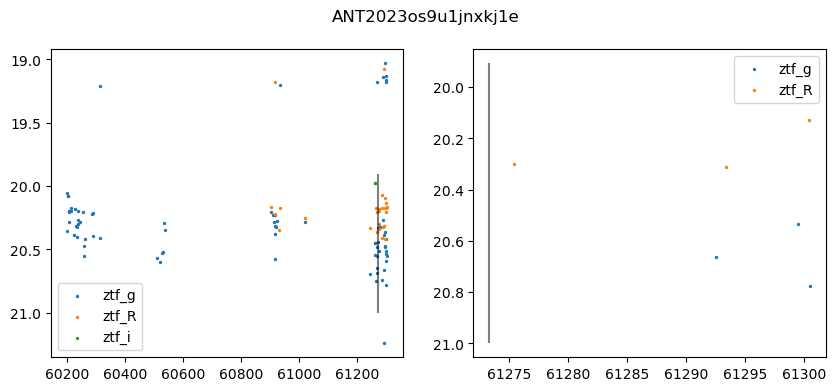

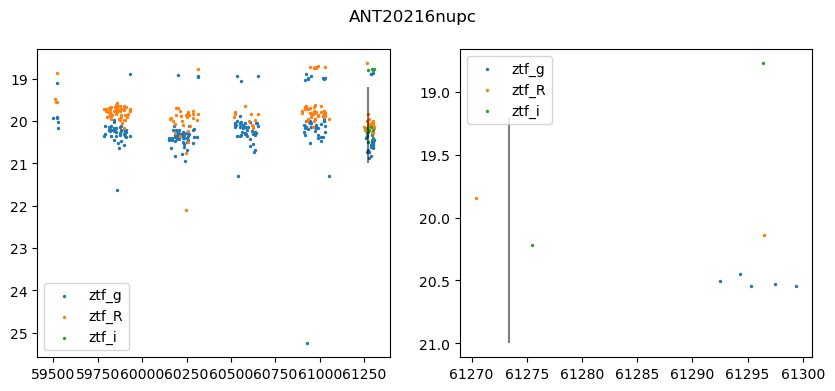

In [98]:
i = 0
for oid_id in list(oid_sample.keys())[j:j+10]:
    fig, ax = plt.subplots(1,2, figsize=(10,4))
    # print(oid_id)
    locus = search.get_by_id(oid_id)
    lc = lightcurve(locus.alerts)
    for band in lc:
        if isinstance(lc[band], pd.DataFrame) == 0:
            continue
        ax[0].scatter(lc[band]['mjd'], lc[band]['mag'], s=2, label=band)
        
        if isinstance(oid_sample[oid_id][band], pd.DataFrame) == 0:
            continue
        ax[1].scatter(oid_sample[oid_id][band]['mjd'], oid_sample[oid_id][band]['oid_mag'], s=2, label=band)
        
    ax[0].legend()
    ax[0].vlines(x=locus.properties['newest_alert_observation_time']-30, ymin= 21, ymax = locus.properties['brightest_alert_magnitude'],
             colors='k', alpha = 0.5)
    ax[0].yaxis.set_inverted(True)
    ax[1].legend()
    ax[1].vlines(x=locus.properties['newest_alert_observation_time']-30, ymin= 21, ymax = locus.properties['brightest_alert_magnitude'],
             colors='k', alpha = 0.5)
    ax[1].yaxis.set_inverted(True)
    fig.suptitle(oid_id)
    i+=1
j+=10
    # print(lc)

In [173]:
# "ANT2020k2kcs"
# "ANT2020k4np2"
# "ANT2020mbpo4"
# "ANT2018gdlcg"
oid_sample['ANT20216nupc']

0

In [114]:
len(targets.drop_duplicates())

503